# Task 2 Neural network surrogates for TGLF
**Calderon · DSC 180A · October 25, 2026**

This notebook builds on the two supplied groupmate presentations. Their model-family comparison motivates testing neural networks only. A training-mean predictor remains as the baseline required by Task 2. This is an independent experiment, not a reproduction of their scores: their notebooks, trained weights and exact splits were not supplied.

We compare network size, depth and target transformations, then compare the best single network with a three-seed ensemble using **validation data only**. The random test split and 43 SAT3 cases are used only after the choice is frozen. All reported flux errors are in the original gyro-Bohm units, after inverse transformation.

**Run:** put this notebook beside `scan_db.tar`, with `SAT3_dataset.tar` in the sibling `Task 1` folder (or edit the two paths below). Run all cells in order. Python 3.12 with numpy, pandas, torch, scikit-learn, matplotlib and IPython is required. The optional `.packages` folder contains the local environment used here. Exact versions are recorded at the end. Training uses one CPU thread and can take several minutes. The notebook writes tables, figures, predictions and model weights to `results/`.

In [1]:
from pathlib import Path
import os, sys, json, time, copy, tarfile, hashlib, platform, importlib.metadata
ROOT = next((p for p in [Path.cwd(), Path.cwd() / 'Task 2', Path.cwd() / 'notebooks' / 'jscalderon' / 'Task 2'] if (p / 'scan_db.tar').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run from Task 2, notebooks/jscalderon, or the repository root; scan_db.tar must be in Task 2.')
if (ROOT / '.packages').exists():
    sys.path.insert(0, str(ROOT / '.packages'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.build' / 'mpl'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from IPython.display import display
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False})
SCAN_ARCHIVE = ROOT / 'scan_db.tar'
SAT3_ARCHIVE = ROOT.parent / 'Task 1' / 'SAT3_dataset.tar'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
SEED = 42
TARGETS = ['Q_i', 'Q_e', 'Gamma_e']
FEATURES = ['RLTS_1','RLTS_2','RLNS_1','TAUS_2','log10_XNUE','Q_LOC',
            'Q_PRIME_LOC','KAPPA_LOC','DRMAJDX_LOC','RMIN_LOC','MASS_2']

## Read and audit the two archives
The generated input file uses **value then parameter name**. For two species, `out.tglf.gbflux` lists both particle fluxes first, then both heat fluxes. Species 1 is the electron and species 2 is the main ion, so zero-based columns 3, 2 and 0 give Q_i, Q_e and Gamma_e. We verify species, saturation rule and units in every case. The folder name SAT3 refers to the source database; these targets are its **TGLF SAT2** outputs, not CGYRO targets.

Archives are read directly, without extracting their contents. Missing or malformed files stop the run rather than silently losing cases.

In [2]:
def read_archive(path):
    rows=[]
    with tarfile.open(path, 'r:*') as archive:
        members = {m.name: m for m in archive.getmembers() if m.isfile()}
        inputs = sorted(n for n in members if n.endswith('/tglf_sat2/input.tglf.gen'))
        for name in inputs:
            params={}
            for line in archive.extractfile(members[name]).read().decode().splitlines():
                parts=line.split()
                if len(parts) >= 2:
                    value,key=parts[:2]
                    try: value=float(value.replace('D','E').replace('d','e'))
                    except ValueError: pass
                    params[key]=value
            assert params['NS']==2 and params['ZS_1']==-1 and params['ZS_2']==1
            assert params['SAT_RULE']==2 and params['UNITS']=='GYRO'
            flux_name=name.rsplit('/',1)[0]+'/out.tglf.gbflux'
            raw=archive.extractfile(members[flux_name]).read().decode()
            flux=np.fromstring(raw.replace('D','E').replace('d','e'),sep=' ')
            assert flux.size==8, (name, flux.size)
            rows.append({'case':name.split('/')[-3],**params,
                         'Q_i':flux[3], 'Q_e':flux[2], 'Gamma_e':flux[0]})
    return pd.DataFrame(rows).set_index('case')

scan_raw=read_archive(SCAN_ARCHIVE)
sat_raw=read_archive(SAT3_ARCHIVE)
assert len(scan_raw)==5000 and len(sat_raw)==43
assert scan_raw.index.is_unique and sat_raw.index.is_unique
for frame in (scan_raw,sat_raw):
    assert (frame.XNUE>0).all()
    assert np.allclose(frame.RLNS_1,frame.RLNS_2)
    frame['log10_XNUE']=np.log10(frame.XNUE)

# Assign all 5000 case IDs once, before any cleaning or fitted preprocessing.
train_ids, held_ids = train_test_split(scan_raw.index.to_numpy(),test_size=.30,random_state=SEED)
val_ids,test_ids = train_test_split(held_ids,test_size=.50,random_state=SEED)
split=pd.Series(index=scan_raw.index,dtype='object',name='split')
for name,ids in [('train',train_ids),('validation',val_ids),('test',test_ids)]: split.loc[ids]=name
valid=(np.isfinite(scan_raw[FEATURES+TARGETS]).all(axis=1)
       & (scan_raw[['Q_i','Q_e']]>0).all(axis=1))
excluded=scan_raw.loc[~valid,TARGETS].join(split)
print('Excluded cases (nonfinite values or nonpositive heat flux):')
display(excluded)
scan=scan_raw.loc[valid].copy()
train=scan.loc[[i for i in train_ids if valid.loc[i]]]
val=scan.loc[[i for i in val_ids if valid.loc[i]]]
test=scan.loc[[i for i in test_ids if valid.loc[i]]]
sat=sat_raw.copy()
assert np.isfinite(sat[FEATURES+TARGETS]).all().all() and (sat[['Q_i','Q_e']]>0).all().all()
assert not (set(train.index)&set(val.index) or set(train.index)&set(test.index) or set(val.index)&set(test.index))
assert not scan[FEATURES].duplicated().any(), 'Duplicate inputs need grouped splitting.'
assert not set(map(tuple,scan[FEATURES].to_numpy())) & set(map(tuple,sat[FEATURES].to_numpy()))
split.to_csv(OUT/'split_assignments.csv')
excluded.to_csv(OUT/'excluded_cases.csv')
scan_raw[FEATURES+TARGETS].to_csv(OUT/'scan_table.csv')
sat[FEATURES+TARGETS].to_csv(OUT/'sat3_table.csv')
print('Usable split sizes:',{k:len(v) for k,v in [('train',train),('validation',val),('test',test)]})
print('Signed particle flux cases retained:',int((scan.Gamma_e<0).sum()))
display(scan[TARGETS].describe().T)

Excluded cases (nonfinite values or nonpositive heat flux):
Usable split sizes: {'train': 3496, 'validation': 750, 'test': 750}
Signed particle flux cases retained: 45


,Q_i,Q_e,Gamma_e,split
case,,,,
r0702,-16.668000,236.6000,1.587000,train
r2002,-0.241370,31.9940,-0.012923,train
r2828,-0.018705,6.8269,-0.013826,train
r3565,-1.650400,30.4410,0.102810,train


,count,mean,std,min,25%,50%,75%,max
Q_i,4996.0,62.785229,86.696717,0.119040,14.32325,34.2115,74.19475,1050.40
Q_e,4996.0,50.125050,69.981947,0.048878,11.63450,25.1490,57.90375,813.52
Gamma_e,4996.0,15.788369,24.525345,-5.025800,2.86395,6.9146,18.44575,283.13


## Inputs and output scales
We retain 11 physically specified inputs, drop constant settings and keep only one of the identical density-gradient columns. Ion mass stays numeric. `XNUE` is sampled on a logarithmic scale, so its log10 is the feature expected to look uniform. `Q_PRIME_LOC` is a dependent magnetic-geometry term and need not have a flat histogram. We retain that supplied term rather than assume a shear conversion convention.

The log-target candidates use log10 for the positive heat fluxes and leave particle flux signed. One alternative uses asinh(Gamma_e / s), with s equal to the median absolute training particle flux. A raw-target alternative tests whether transformations help. Target and feature scaling are fitted separately for every training subset.

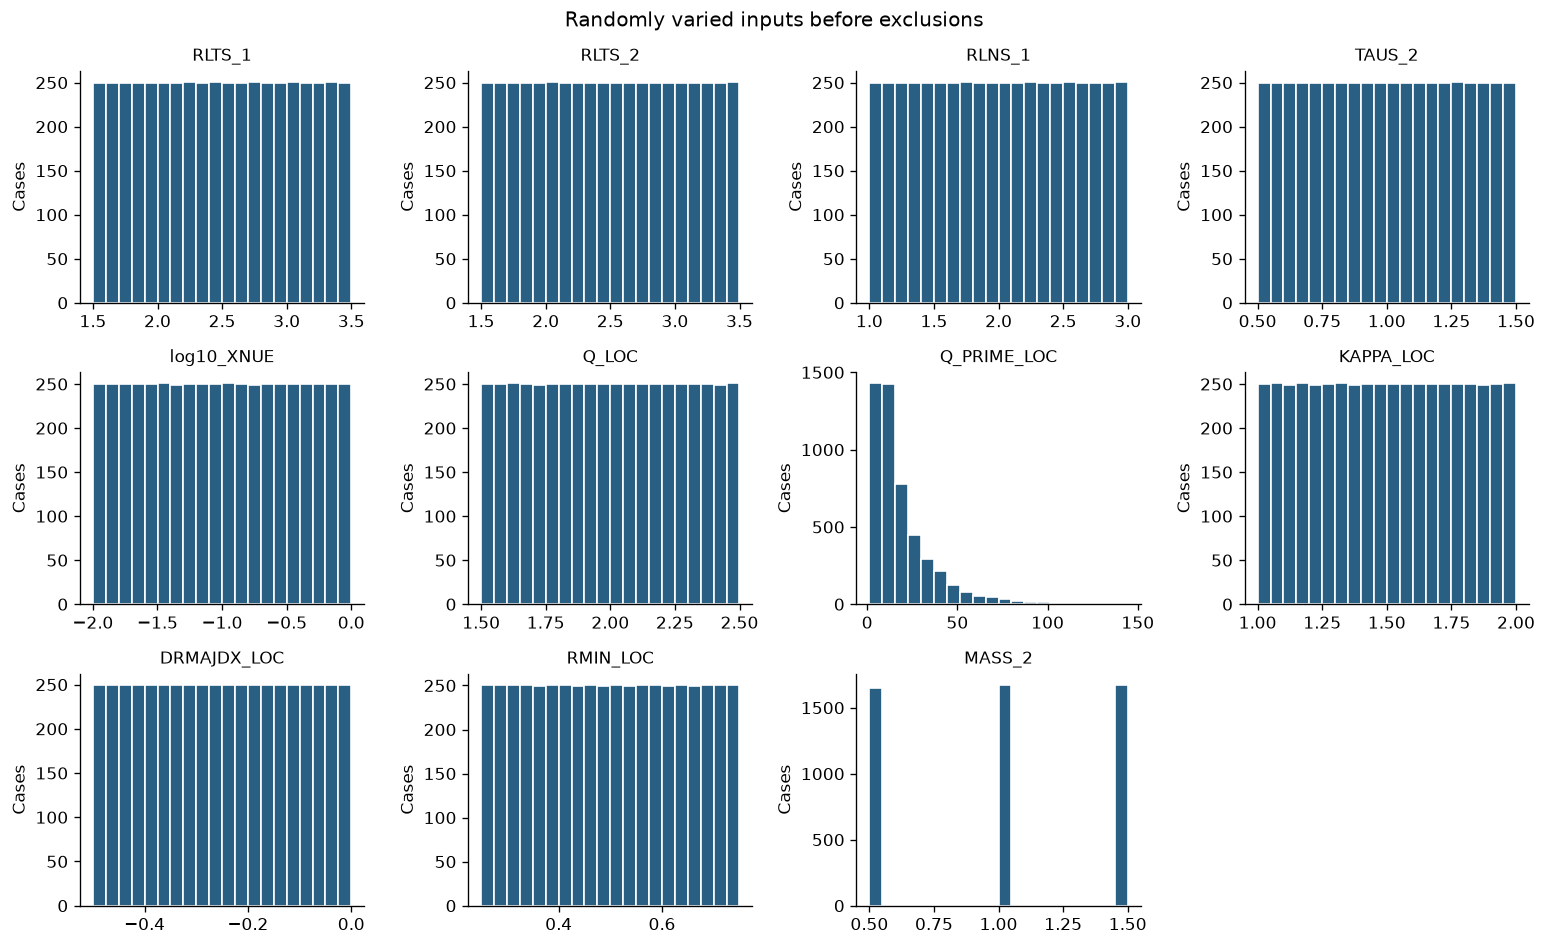

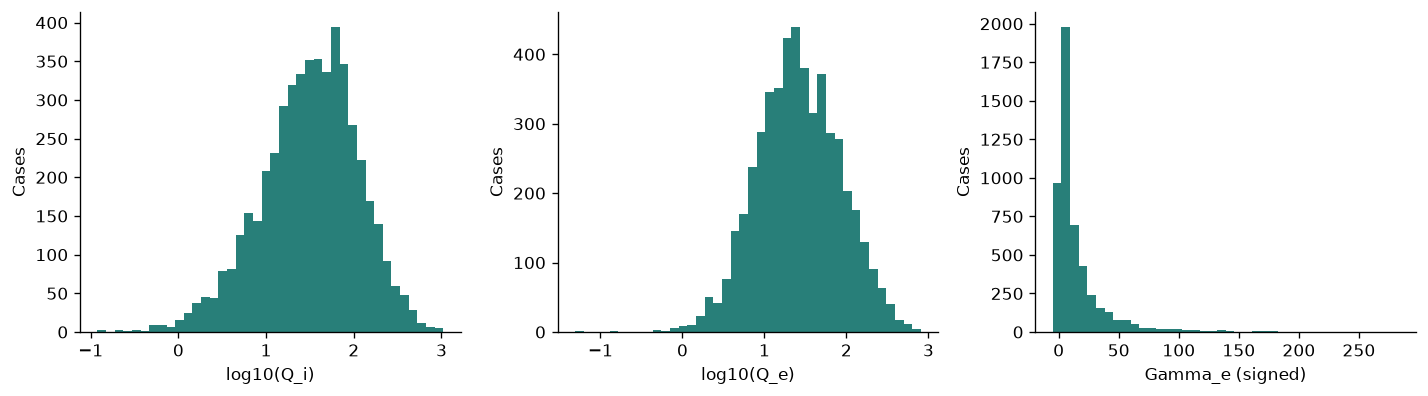

In [3]:
fig,axes=plt.subplots(3,4,figsize=(13,8))
for ax,name in zip(axes.flat,FEATURES):
    ax.hist(scan_raw[name],bins=20,color='#285f82',edgecolor='white')
    ax.set_title(name,fontsize=10);ax.set_ylabel('Cases')
axes.flat[-1].axis('off');fig.suptitle('Randomly varied inputs before exclusions');fig.tight_layout()
fig.savefig(OUT/'input_histograms.png',bbox_inches='tight');plt.show()
fig,axes=plt.subplots(1,3,figsize=(12,3.4))
for j,name in enumerate(TARGETS):
    values=np.log10(scan[name]) if j<2 else scan[name]
    axes[j].hist(values,bins=40,color='#287f79')
    axes[j].set_xlabel('log10('+name+')' if j<2 else name+' (signed)')
    axes[j].set_ylabel('Cases')
fig.tight_layout();fig.savefig(OUT/'output_histograms.png',bbox_inches='tight');plt.show()

## Neural networks and validation protocol
All candidates use GELU hidden activations and a linear three-output head, AdamW with learning rate 0.001 and weight decay 0.0001, batch size 256, and at most 600 epochs. Early stopping uses **mean validation nRMSE in original units**, with patience 70 epochs. Here nRMSE is RMSE divided by each target's training standard deviation. We select the best checkpoint, not the final epoch.

The six planned candidates share seed 42 and the same data split. We then train two additional seeds (43 and 44) of the best architecture and compare its three-network average against the original single network on validation. Averaging occurs after inverse transformation. These are limited experiments, not an exhaustive architecture search.

In [4]:
class TargetTransform:
    def __init__(self,mode): self.mode=mode
    def fit(self,y):
        self.gamma_scale=max(float(np.median(np.abs(y[:,2]))),1e-6)
        self.scaler=StandardScaler().fit(self.forward(y))
        return self
    def forward(self,y):
        z=y.copy()
        if self.mode!='raw': z[:,:2]=np.log10(z[:,:2])
        if self.mode=='log_asinh': z[:,2]=np.arcsinh(z[:,2]/self.gamma_scale)
        return z
    def transform(self,y): return self.scaler.transform(self.forward(y))
    def inverse(self,z):
        y=self.scaler.inverse_transform(z)
        if self.mode!='raw': y[:,:2]=10.**y[:,:2]
        if self.mode=='log_asinh': y[:,2]=np.sinh(y[:,2])*self.gamma_scale
        return y

def make_model(widths):
    layers=[];last=len(FEATURES)
    for width in widths:
        layers += [nn.Linear(last,width),nn.GELU()];last=width
    return nn.Sequential(*layers,nn.Linear(last,3))

def predict(fit,x):
    fit['model'].eval()
    with torch.inference_mode():
        z=fit['model'](torch.as_tensor(fit['xs'].transform(x),dtype=torch.float32)).numpy()
    return fit['ys'].inverse(z)

def train_model(config,train_frame,seed=SEED,max_epochs=600,patience=70):
    started=time.perf_counter()
    torch.manual_seed(seed)
    rng=np.random.default_rng(seed)
    x=train_frame[FEATURES].to_numpy();y=train_frame[TARGETS].to_numpy()
    xs=StandardScaler().fit(x);ys=TargetTransform(config['mode']).fit(y)
    xt=torch.tensor(xs.transform(x),dtype=torch.float32)
    yt=torch.tensor(ys.transform(y),dtype=torch.float32)
    xv=torch.tensor(xs.transform(val[FEATURES].to_numpy()),dtype=torch.float32)
    yv=val[TARGETS].to_numpy();scale=y.std(axis=0)
    model=make_model(config['widths']);optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.0001)
    best=float('inf');best_epoch=0;best_state=None;history=[]
    for epoch in range(1,max_epochs+1):
        model.train();loss_sum=0.
        for idx in np.array_split(rng.permutation(len(x)),int(np.ceil(len(x)/256))):
            optimizer.zero_grad(set_to_none=True)
            loss=nn.functional.mse_loss(model(xt[idx]),yt[idx]);loss.backward();optimizer.step()
            loss_sum += loss.item()*len(idx)
        model.eval()
        with torch.inference_mode(): pv=ys.inverse(model(xv).numpy())
        score=float(np.mean(np.sqrt(np.mean((pv-yv)**2,axis=0))/scale))
        history.append([epoch,loss_sum/len(x),score])
        if np.isfinite(score) and score<best-1e-6:
            best=score;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict())
        if epoch-best_epoch>=patience: break
    assert best_state is not None
    model.load_state_dict(best_state)
    return {'model':model,'xs':xs,'ys':ys,'config':config,'seed':seed,
            'best_epoch':best_epoch,'epochs_run':epoch,'validation_score':best,
            'history':history,'train_seconds':time.perf_counter()-started,
            'parameters':sum(p.numel() for p in model.parameters())}

CONFIGS=[
    {'name':'Small 32-32','widths':[32,32],'mode':'log'},
    {'name':'Medium 64-64','widths':[64,64],'mode':'log'},
    {'name':'Wide 128-128','widths':[128,128],'mode':'log'},
    {'name':'Deep 64-64-64','widths':[64,64,64],'mode':'log'},
    {'name':'Medium signed asinh','widths':[64,64],'mode':'log_asinh'},
    {'name':'Medium raw targets','widths':[64,64],'mode':'raw'}]
fits=[]
for config in CONFIGS:
    fit=train_model(config,train);fits.append(fit)
    print(config['name'], 'validation nRMSE',round(fit['validation_score'],4),
          'best epoch',fit['best_epoch'],'seconds',round(fit['train_seconds'],1),flush=True)
validation=pd.DataFrame([{'model':f['config']['name'],'parameters':f['parameters'],
                         'mean_validation_nRMSE':f['validation_score'],
                         'best_epoch':f['best_epoch'],'epochs_run':f['epochs_run'],
                         'training_seconds':f['train_seconds']} for f in fits])
best_single=min(fits,key=lambda f:f['validation_score'])
members=[best_single]+[train_model(best_single['config'],train,seed=s) for s in [43,44]]
def ensemble_predict(members,x): return np.mean([predict(f,x) for f in members],axis=0)
train_scale=train[TARGETS].to_numpy().std(axis=0)
ensemble_val=ensemble_predict(members,val[FEATURES].to_numpy())
ensemble_score=float(np.mean(np.sqrt(np.mean((ensemble_val-val[TARGETS].to_numpy())**2,axis=0))/train_scale))
use_ensemble=ensemble_score<best_single['validation_score']
selected_members=members if use_ensemble else [best_single]
selected_name=('3-seed ensemble of ' if use_ensemble else '')+best_single['config']['name']
validation.loc[len(validation)]={'model':'3-seed ensemble','parameters':sum(f['parameters'] for f in members),
    'mean_validation_nRMSE':ensemble_score,'best_epoch':None,'epochs_run':None,
    'training_seconds':sum(f['train_seconds'] for f in members)}
validation.to_csv(OUT/'validation_comparison.csv',index=False)
display(validation.round(5));print('Frozen selected model:',selected_name)

Small 32-32 validation nRMSE 0.2266 best epoch 473 seconds 6.7
Medium 64-64 validation nRMSE 0.2221 best epoch 272 seconds 5.1
Wide 128-128 validation nRMSE 0.2262 best epoch 153 seconds 7.2
Deep 64-64-64 validation nRMSE 0.2043 best epoch 196 seconds 5.8
Medium signed asinh validation nRMSE 0.2249 best epoch 303 seconds 5.3
Medium raw targets validation nRMSE 0.2258 best epoch 244 seconds 3.5
Frozen selected model: 3-seed ensemble of Deep 64-64-64


,model,parameters,mean_validation_nRMSE,best_epoch,epochs_run,training_seconds
0,Small 32-32,1539,0.22663,473.0,543.0,6.65204
1,Medium 64-64,5123,0.22206,272.0,342.0,5.07693
2,Wide 128-128,18435,0.22623,153.0,223.0,7.23482
3,Deep 64-64-64,9283,0.20426,196.0,266.0,5.80223
4,Medium signed asinh,5123,0.22486,303.0,373.0,5.32965
5,Medium raw targets,5123,0.22582,244.0,314.0,3.53496
6,3-seed ensemble,27849,0.18898,NaN,NaN,16.46420


## Final test and outside-test accuracy
The baseline always predicts the **arithmetic mean of the original training fluxes**. It has no fitted architecture or tuned settings. Both models use identical test cases. We report per-output RMSE, R² and nRMSE using the same training standard deviations for both evaluation sets. R² on SAT3 uses the SAT3 target variance, so compare absolute RMSE and nRMSE as well as R² across datasets. No SAT3 values are used for fitting or selecting a model.

,dataset,model,output,n,RMSE,R2,nRMSE
0,Random test,Mean baseline,Q_i,750,76.53008,-0.00887,0.86579
1,Random test,Mean baseline,Q_e,750,60.20469,-0.00951,0.82904
2,Random test,Mean baseline,Gamma_e,750,20.92549,-0.01094,0.82674
3,Random test,Selected NN,Q_i,750,17.12520,0.94948,0.19374
4,Random test,Selected NN,Q_e,750,12.70044,0.95507,0.17489
5,Random test,Selected NN,Gamma_e,750,3.45311,0.97247,0.13643
6,SAT3,Mean baseline,Q_i,43,31.57939,-0.66831,0.35726
7,SAT3,Mean baseline,Q_e,43,36.55315,-1.04784,0.50335
8,SAT3,Mean baseline,Gamma_e,43,14.19770,-0.98737,0.56093
9,SAT3,Selected NN,Q_i,43,5.50862,0.94924,0.06232


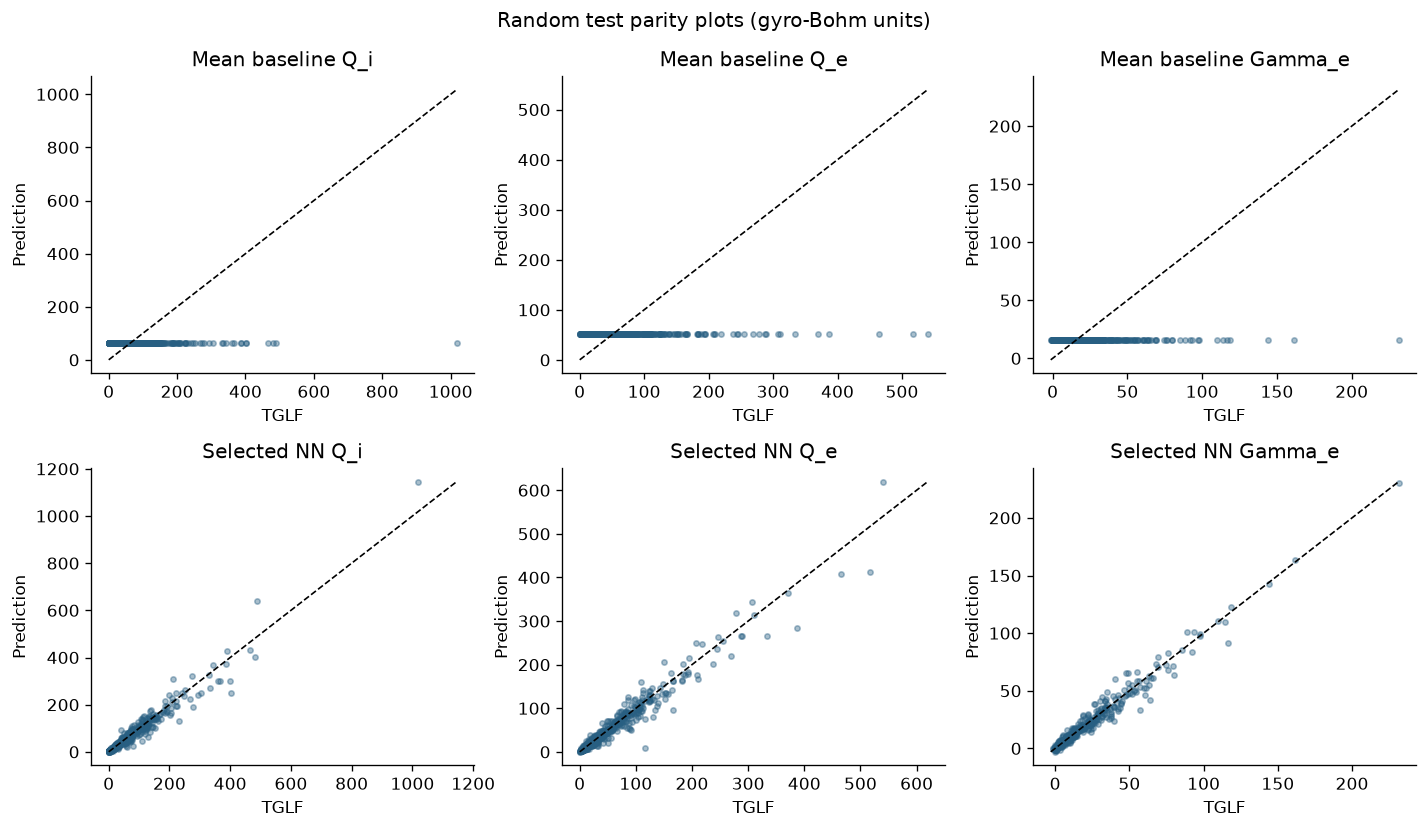

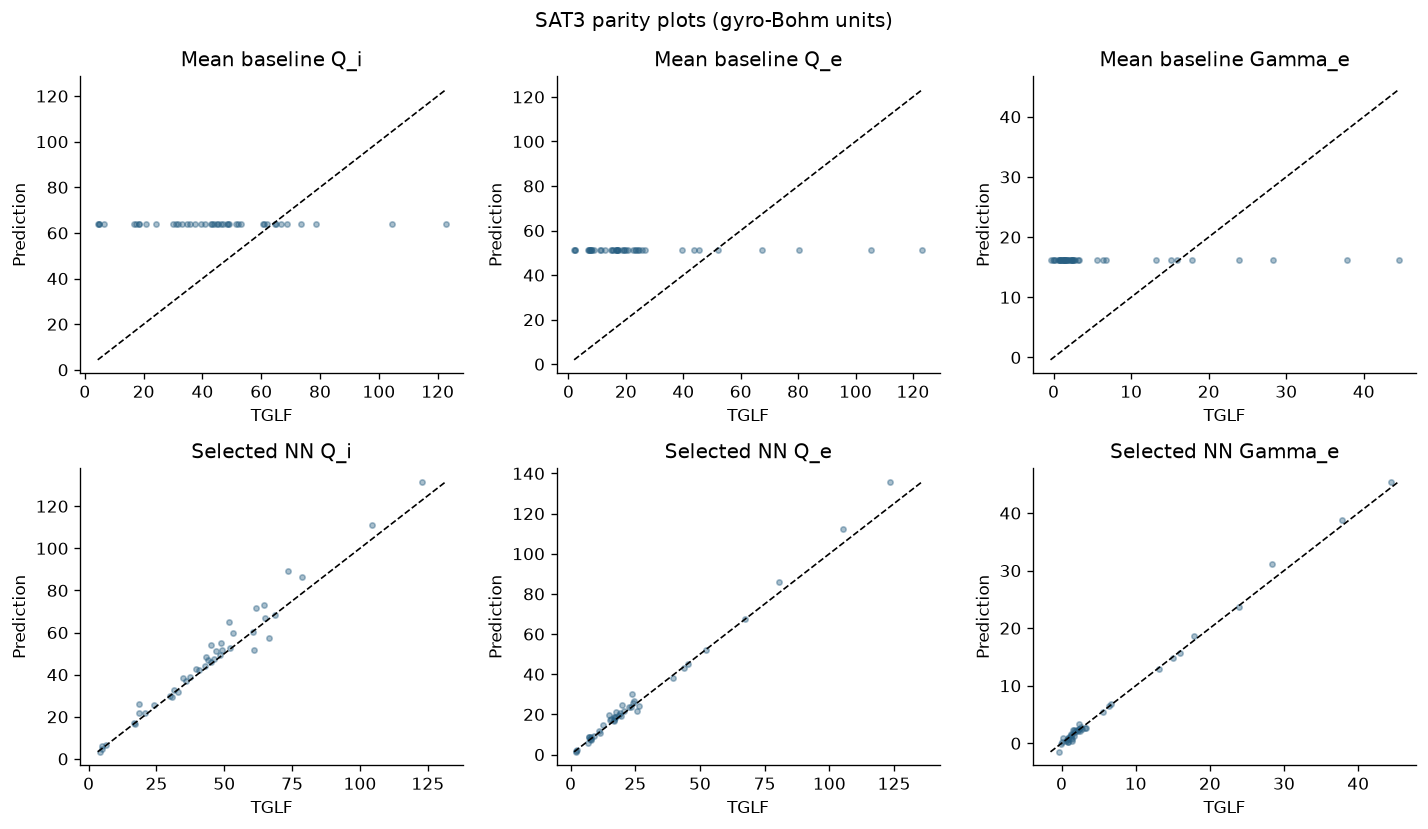

In [5]:
mean_flux=train[TARGETS].mean().to_numpy()
def metrics(y,p,dataset,model):
    rmse=np.sqrt(np.mean((p-y)**2,axis=0))
    r2=r2_score(y,p,multioutput='raw_values')
    return [{'dataset':dataset,'model':model,'output':name,'n':len(y),
             'RMSE':float(rmse[j]),'R2':float(r2[j]),'nRMSE':float(rmse[j]/train_scale[j])}
            for j,name in enumerate(TARGETS)]
metric_rows=[];predictions={}
for name,frame in [('Random test',test),('SAT3',sat)]:
    y=frame[TARGETS].to_numpy()
    pred=ensemble_predict(selected_members,frame[FEATURES].to_numpy())
    base=np.tile(mean_flux,(len(frame),1));predictions[name]=pred
    metric_rows += metrics(y,base,name,'Mean baseline')+metrics(y,pred,name,'Selected NN')
    table=frame[TARGETS].copy()
    for j,target in enumerate(TARGETS):
        table[target+'_NN']=pred[:,j];table[target+'_mean']=base[:,j]
    table.to_csv(OUT/('test_predictions.csv' if name=='Random test' else 'sat3_predictions.csv'))
metric_table=pd.DataFrame(metric_rows)
metric_table.to_csv(OUT/'metrics.csv',index=False)
display(metric_table.round(5))

for dataset,frame in [('Random test',test),('SAT3',sat)]:
    fig,axes=plt.subplots(2,3,figsize=(12,7))
    for row,model in enumerate(['Mean baseline','Selected NN']):
        pred=np.tile(mean_flux,(len(frame),1)) if row==0 else predictions[dataset]
        for j,target in enumerate(TARGETS):
            ax=axes[row,j];true=frame[target].to_numpy()
            ax.scatter(true,pred[:,j],s=10,alpha=.4,color='#285f82')
            lo=min(true.min(),pred[:,j].min());hi=max(true.max(),pred[:,j].max())
            ax.plot([lo,hi],[lo,hi],'k--',lw=1)
            ax.set_title(model+' '+target);ax.set_xlabel('TGLF');ax.set_ylabel('Prediction')
    fig.suptitle(dataset+' parity plots (gyro-Bohm units)');fig.tight_layout()
    fig.savefig(OUT/(dataset.replace(' ','_')+'_parity.png'),bbox_inches='tight');plt.show()

## Learning curves without changing the selected architecture
The architecture and target transformation are fixed above. For each training size, three deterministic permutations create nested training subsets, and three initialization seeds show sensitivity to subset selection and training. Each subset gets its own scalers and mean baseline. The same validation split controls early stopping. Test error is displayed as the assignment requests, but is **not used to make any further model choices**.

For an ensemble winner, each curve point is an ensemble of three networks on that subset. Curves show average per-output nRMSE across three repetitions, with one-standard-deviation bands. The denominator is always the full training-set standard deviation, so values remain comparable across training sizes. These bands are descriptive variation, not confidence intervals.

Learning curve 1 250 cases complete
Learning curve 1 500 cases complete
Learning curve 1 1000 cases complete
Learning curve 1 2000 cases complete
Learning curve 1 3496 cases complete
Learning curve 2 250 cases complete
Learning curve 2 500 cases complete
Learning curve 2 1000 cases complete
Learning curve 2 2000 cases complete
Learning curve 2 3496 cases complete
Learning curve 3 250 cases complete
Learning curve 3 500 cases complete
Learning curve 3 1000 cases complete
Learning curve 3 2000 cases complete
Learning curve 3 3496 cases complete


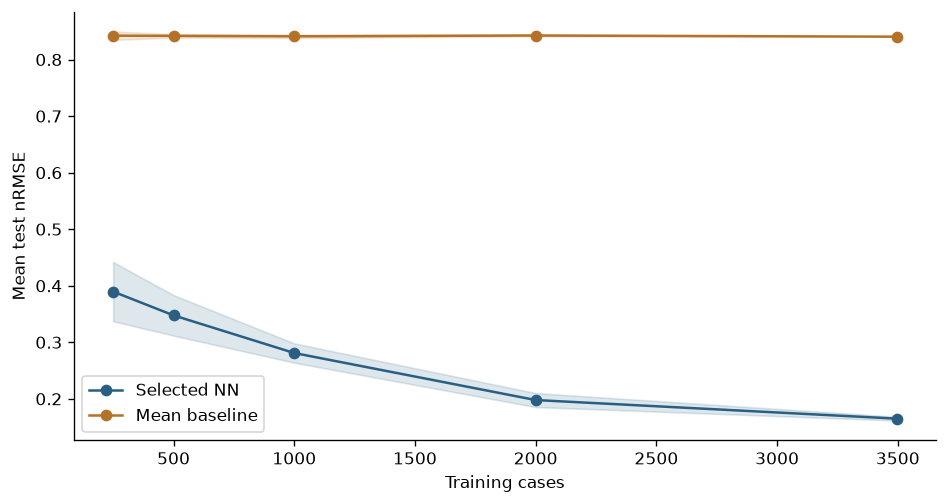

mean      std
model         training_n                  
Mean baseline 250         0.84228  0.00746
              500         0.84195  0.00313
              1000        0.84115  0.00299
              2000        0.84258  0.00160
              3496        0.84052  0.00000
Selected NN   250         0.38958  0.05241
              500         0.34764  0.03580
              1000        0.28101  0.01707
              2000        0.19784  0.01236
              3496        0.16494  0.00335

In [6]:
learning=[]
sizes=[250,500,1000,2000,len(train)]
for rep in range(3):
    ordering=np.random.default_rng(100+rep).permutation(len(train))
    for n in sizes:
        subset=train.iloc[ordering[:n]]
        if n==len(train) and rep==0:
            curve_members=selected_members
        else:
            curve_members=[train_model(best_single['config'],subset,seed=1000+rep*10+k)
                           for k in range(len(selected_members))]
        p=ensemble_predict(curve_members,test[FEATURES].to_numpy())
        base=np.tile(subset[TARGETS].mean().to_numpy(),(len(test),1))
        for model,pr in [('Selected NN',p),('Mean baseline',base)]:
            vals=np.sqrt(np.mean((pr-test[TARGETS].to_numpy())**2,axis=0))/train_scale
            learning.append({'repeat':rep,'training_n':n,'model':model,
                             'mean_nRMSE':float(vals.mean()),**dict(zip(TARGETS,vals))})
        print('Learning curve',rep+1,n,'cases complete',flush=True)
learning=pd.DataFrame(learning)
learning.to_csv(OUT/'learning_curves.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4.3))
for model,color in [('Selected NN','#285f82'),('Mean baseline','#b57126')]:
    grouped=learning[learning.model==model].groupby('training_n').mean_nRMSE.agg(['mean','std'])
    ax.plot(grouped.index,grouped['mean'],'o-',label=model,color=color)
    ax.fill_between(grouped.index,grouped['mean']-grouped['std'],grouped['mean']+grouped['std'],alpha=.15,color=color)
ax.set_xlabel('Training cases');ax.set_ylabel('Mean test nRMSE');ax.legend()
fig.tight_layout();fig.savefig(OUT/'learning_curve.png',bbox_inches='tight');plt.show()
display(learning.groupby(['model','training_n']).mean_nRMSE.agg(['mean','std']).round(5))

## CPU timing
The timing includes feature standardization, neural-network inference and inverse target transformation. It excludes disk I/O and archive parsing. Report the median of repeated, warmed-up calls for one case and for the full test batch. Batch time divided by case count measures throughput, not single-case latency. All timings use one CPU thread on this machine. TGLF's “seconds per case” is the assignment's qualitative reference, not a TGLF benchmark measured here, so no measured speedup ratio is claimed.

In [7]:
def latency(fn,repeats):
    for _ in range(15): fn()
    elapsed=[]
    for _ in range(repeats):
        start=time.perf_counter_ns();fn();elapsed.append((time.perf_counter_ns()-start)/1e6)
    return float(np.median(elapsed))
x_test=test[FEATURES].to_numpy()
single_ms=latency(lambda:ensemble_predict(selected_members,x_test[:1]),300)
batch_ms=latency(lambda:ensemble_predict(selected_members,x_test),100)
baseline_ms=latency(lambda:np.tile(mean_flux,(1,1)),300)
timing={'selected_single_case_ms':single_ms,'selected_batch_ms':batch_ms,
        'selected_batch_ms_per_case':batch_ms/len(test),'baseline_single_case_ms':baseline_ms,
        'selected_model_training_seconds':sum(f['train_seconds'] for f in selected_members),
        'all_candidate_and_extra_seed_training_seconds':sum(f['train_seconds'] for f in fits)+sum(f['train_seconds'] for f in members[1:]),
        'cpu_threads':1,'platform':platform.platform(),'machine':platform.machine()}
display(pd.Series(timing,name='Value'))

selected_single_case_ms                                              0.977062
selected_batch_ms                                                    2.258354
selected_batch_ms_per_case                                           0.003011
baseline_single_case_ms                                              0.001458
selected_model_training_seconds                                     16.464199
all_candidate_and_extra_seed_training_seconds                         44.2926
cpu_threads                                                                 1
platform                                         macOS-26.6.2-arm64-arm-64bit
machine                                                                 arm64
Name: Value, dtype: object

## SAT3 scan trends and domain coverage
We inspect the b, c, a, d temperature-gradient scan for deuterium and all eight complete H/D/T triplets. Both temperature gradients change together in the temperature scan, so this cannot isolate their individual effects. Lines connect supplied simulation cases rather than imply extra simulations. Trend agreement is descriptive on this small outside test.

The SAT3 cases use a different sampling design but related physics and input ranges. They test transfer to these particular scans, not arbitrary extrapolation. We report input-range coverage explicitly, allowing small tolerance for endpoints because random samples rarely reach exact stated bounds.

Signed and positivity checks: {'Random test': {'negative_particle_cases': 7, 'negative_particle_sign_correct': 3, 'negative_predicted_heat_values': 0}, 'SAT3': {'negative_particle_cases': 2, 'negative_particle_sign_correct': 2, 'negative_predicted_heat_values': 0}}


,feature,train_min,train_max,SAT3_min,SAT3_max,outside_observed_range_n
0,RLTS_1,1.500070,3.499230,1.50,3.50,0
1,RLTS_2,1.501150,3.498660,1.50,3.50,0
2,RLNS_1,1.001370,2.999640,1.00,3.00,0
3,TAUS_2,0.500078,1.499680,0.50,1.50,0
4,log10_XNUE,-1.999293,-0.001772,-2.00,0.00,0
5,Q_LOC,1.500070,2.499720,1.50,2.50,0
6,Q_PRIME_LOC,1.346970,144.444000,4.00,64.00,0
7,KAPPA_LOC,1.000720,1.999820,1.00,2.00,0
8,DRMAJDX_LOC,-0.499800,-0.000014,-0.50,0.00,0
9,RMIN_LOC,0.250001,0.749910,0.25,0.75,0


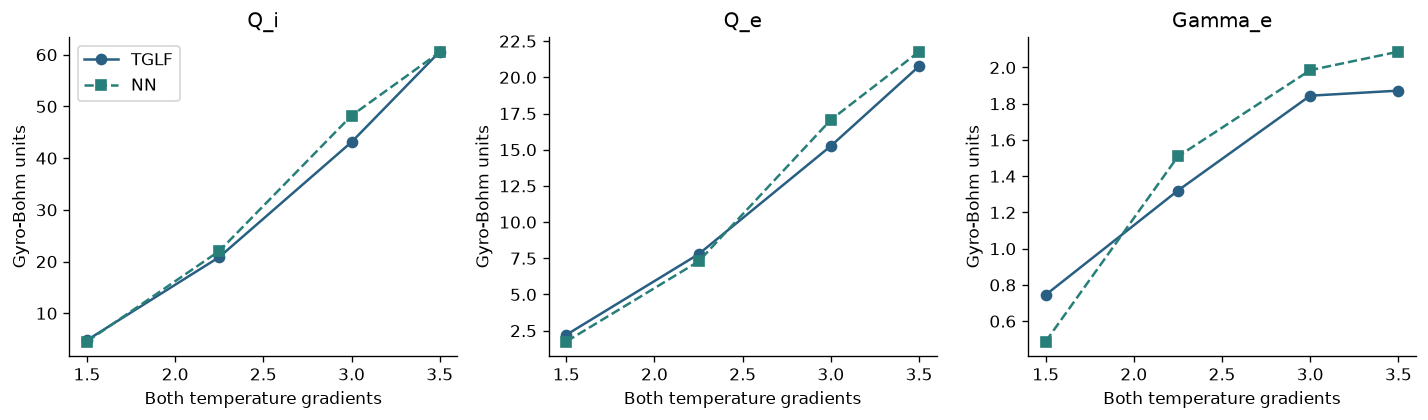

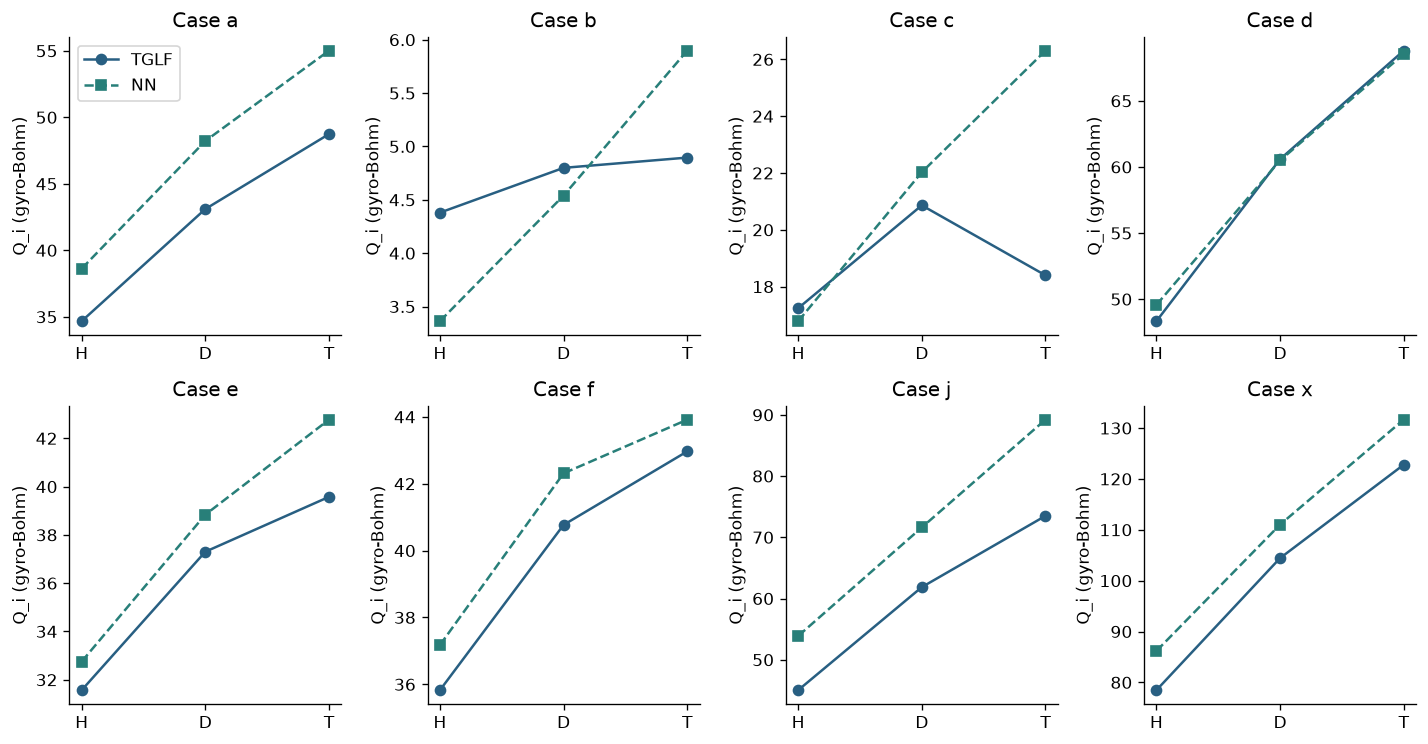

,case,TGLF_order,NN_order,ordering_matches
0,a,"H,D,T","H,D,T",True
1,b,"H,D,T","H,D,T",True
2,c,"H,T,D","H,D,T",False
3,d,"H,D,T","H,D,T",True
4,e,"H,D,T","H,D,T",True
5,f,"H,D,T","H,D,T",True
6,j,"H,D,T","H,D,T",True
7,x,"H,D,T","H,D,T",True


In [8]:
sat_pred=pd.DataFrame(predictions['SAT3'],index=sat.index,columns=TARGETS)
coverage=[]
for f in FEATURES:
    low,high=train[f].min(),train[f].max();tol=.002*max(high-low,1e-6)
    outside=(sat[f]<low-tol)|(sat[f]>high+tol)
    coverage.append({'feature':f,'train_min':low,'train_max':high,'SAT3_min':sat[f].min(),
                     'SAT3_max':sat[f].max(),'outside_observed_range_n':int(outside.sum())})
coverage=pd.DataFrame(coverage);coverage.to_csv(OUT/'sat3_input_coverage.csv',index=False);display(coverage)
case_order=['b_D','c_D','a_D','d_D']
fig,axes=plt.subplots(1,3,figsize=(12,3.6))
for j,target in enumerate(TARGETS):
    axes[j].plot(sat.loc[case_order,'RLTS_1'],sat.loc[case_order,target],'o-',label='TGLF',color='#285f82')
    axes[j].plot(sat.loc[case_order,'RLTS_1'],sat_pred.loc[case_order,target],'s--',label='NN',color='#287f79')
    axes[j].set_title(target);axes[j].set_xlabel('Both temperature gradients');axes[j].set_ylabel('Gyro-Bohm units')
axes[0].legend();fig.tight_layout();fig.savefig(OUT/'sat3_temperature_scan.png',bbox_inches='tight');plt.show()
letters=[l for l in sorted({s.split('_')[0] for s in sat.index}) if all(l+'_'+iso in sat.index for iso in ['H','D','T'])]
isotope=[]
fig,axes=plt.subplots(2,4,figsize=(12,6.3))
for ax,letter in zip(axes.flat,letters):
    ids=[letter+'_'+iso for iso in ['H','D','T']]
    truth=sat.loc[ids,'Q_i'].to_numpy();p=sat_pred.loc[ids,'Q_i'].to_numpy()
    ax.plot([.5,1,1.5],truth,'o-',label='TGLF',color='#285f82')
    ax.plot([.5,1,1.5],p,'s--',label='NN',color='#287f79')
    ax.set_title('Case '+letter);ax.set_xticks([.5,1,1.5],['H','D','T']);ax.set_ylabel('Q_i (gyro-Bohm)')
    isotope.append({'case':letter,'TGLF_order':','.join(np.array(['H','D','T'])[np.argsort(truth)]),
                    'NN_order':','.join(np.array(['H','D','T'])[np.argsort(p)]),
                    'ordering_matches':bool(np.array_equal(np.argsort(truth),np.argsort(p)))})
axes.flat[0].legend();fig.tight_layout();fig.savefig(OUT/'sat3_isotope_scan.png',bbox_inches='tight');plt.show()
isotope=pd.DataFrame(isotope);isotope.to_csv(OUT/'isotope_ordering.csv',index=False);display(isotope)
signed_checks={}
for label,frame in [('Random test',test),('SAT3',sat)]:
    mask=frame.Gamma_e.to_numpy()<0
    signed_checks[label]={'negative_particle_cases':int(mask.sum()),
        'negative_particle_sign_correct':int((predictions[label][mask,2]<0).sum()),
        'negative_predicted_heat_values':int((predictions[label][:,:2]<=0).sum())}
print('Signed and positivity checks:',signed_checks)

## Save results and reproducibility details
The JSON summary and CSV tables feed the slide deck. Saved checkpoints include feature order, scalers, target-transform parameters and state dictionaries. No hidden training script is required: the model, preprocessing, figures and analysis are all defined in this notebook.

Limitations: selection uses one validation split; three learning-curve repeats do not establish formal uncertainty. The SAT3 test contains only 43 related cases. Relative errors near zero particle flux are unstable, so we use RMSE and sign checks. Timing is hardware dependent. Comparison with groupmate scores is contextual only because their exact code and split are unavailable.

In [9]:
for k,f in enumerate(selected_members):
    torch.save({'state_dict':f['model'].state_dict(),'config':f['config'],'seed':f['seed'],
                'features':FEATURES,'targets':TARGETS,'x_mean':f['xs'].mean_.tolist(),
                'x_scale':f['xs'].scale_.tolist(),'y_mean':f['ys'].scaler.mean_.tolist(),
                'y_scale':f['ys'].scaler.scale_.tolist(),'gamma_scale':f['ys'].gamma_scale},OUT/f'model_member_{k}.pt')
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','torch','scikit-learn','matplotlib','IPython']}
hashes={p.name:hashlib.file_digest(open(p,'rb'),'sha256').hexdigest() for p in [SCAN_ARCHIVE,SAT3_ARCHIVE]}
summary={'selected_name':selected_name,'selected_config':best_single['config'],'ensemble':use_ensemble,
         'split_seed':SEED,'split_sizes':{'train':len(train),'validation':len(val),'test':len(test),'SAT3':len(sat)},
         'excluded':excluded.reset_index().to_dict('records'),'validation':validation.astype(object).where(pd.notna(validation),None).to_dict('records'),
         'metrics':metric_table.to_dict('records'),'timing':timing,'versions':versions,'archive_sha256':hashes,
         'signed_checks':signed_checks,'isotope_order_matches':int(isotope.ordering_matches.sum()),
         'isotope_triplets':len(isotope),'temperature_cases':case_order,
         'temperature_x':sat.loc[case_order,'RLTS_1'].tolist(),
         'temperature_truth':sat.loc[case_order,TARGETS].to_dict('list'),
         'temperature_prediction':sat_pred.loc[case_order,TARGETS].to_dict('list')}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
(OUT/'requirements.txt').write_text(chr(10).join(f'{p}=={v}' for p,v in versions.items())+chr(10))
print('Selected:',selected_name)
display(metric_table[metric_table.model=='Selected NN'].round(4))
print(f'Single-case CPU latency: {single_ms:.3f} ms. Batch throughput: {batch_ms/len(test):.4f} ms/case.')
print(f'Ion heat-flux isotope ordering matched in {int(isotope.ordering_matches.sum())}/{len(isotope)} triplets.')
print('Versions:',versions)

Selected: 3-seed ensemble of Deep 64-64-64
Single-case CPU latency: 0.977 ms. Batch throughput: 0.0030 ms/case.
Ion heat-flux isotope ordering matched in 7/8 triplets.
Versions: {'numpy': '2.5.4', 'pandas': '3.1.0', 'torch': '2.14.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'IPython': '9.17.1'}


,dataset,model,output,n,RMSE,R2,nRMSE
3,Random test,Selected NN,Q_i,750,17.1252,0.9495,0.1937
4,Random test,Selected NN,Q_e,750,12.7004,0.9551,0.1749
5,Random test,Selected NN,Gamma_e,750,3.4531,0.9725,0.1364
9,SAT3,Selected NN,Q_i,43,5.5086,0.9492,0.0623
10,SAT3,Selected NN,Q_e,43,3.0422,0.9858,0.0419
11,SAT3,Selected NN,Gamma_e,43,0.6481,0.9959,0.0256


## Interpretation of the completed experiment

The selected model is a **3-seed ensemble of Deep 64-64-64**. The best single deep network's mean validation nRMSE was 0.2043, compared with 0.2221 for the medium two-layer network. Averaging three seeds reduced it further to 0.1890. Simply increasing width to 128-128 did not outperform the deeper network in this search.

On the random test set, the selected model's R² is **0.949 for ion heat flux, 0.955 for electron heat flux, and 0.972 for electron particle flux**. The corresponding SAT3 scores are **0.949, 0.986, and 0.996**. Both tests beat the training-mean baseline for every output. SAT3 has smaller absolute errors, but it is a small, differently distributed scan set, so that does not establish better performance on arbitrary new plasmas.

Across the three learning-curve repetitions, mean test nRMSE changed from **0.390 at 250 cases** to **0.198 at 2,000** and **0.165 at 3,496**. The mean baseline changed from 0.842 to 0.841. The decrease between 2,000 cases and the full training set suggests more TGLF data could still help, although extrapolating this curve beyond the observed sizes is uncertain.

The selected model took **0.977 ms per single-case CPU call**, including preprocessing and inverse transforms. Training its three members took 16.5 seconds in total, excluding architecture search. Batch throughput is 0.0030 ms per case and should not be confused with individual-call latency.

Ion heat-flux isotope ordering agreed in **7 of 8 complete triplets**. For negative particle-flux cases, the model predicted the negative sign for 3 of 7 random test cases and 2 of 2 SAT3 cases. These local checks qualify the high overall R²: a surrogate can be accurate on average while still missing a subtle ordering or sign.


## Sources
- `Task2_TGLF_surrogate.docx`: required split, metrics, baseline, learning sizes and outside test.
- `Task 2_ Predicting TGLF Results w_ Modeling.pptx`: groupmate model comparison and motivation to focus on neural networks.
- `TGLF_surrogate.pptx`: groupmate neural-network ensemble, log heat targets and signed particle target.
- `scan_db.tar` and `SAT3_dataset.tar`: supplied input files and TGLF SAT2 flux outputs. Dataset hashes and case splits are saved above.